In [20]:
import pandas as pd
import matplotlib.pyplot as plt

path = r"C:\Users\Omkar Jadhav\Documents\zomato.csv"

try:
    df = pd.read_csv(path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(path, encoding="latin-1")

print(df.shape)
print(df.columns.tolist())
df.head()

(7105, 12)
['Unnamed: 0.1', 'Unnamed: 0', 'restaurant name', 'restaurant type', 'rate (out of 5)', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area', 'local address']


,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


In [4]:
# Unnamed columns kadh ani nav sope kar
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df.columns = ["name","type","rating","num_ratings","avg_cost",
              "online_order","table_booking","cuisines","area","address"]
# Duplicates
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

df["rating"] = pd.to_numeric(df["rating"].astype(str).str.replace("/5","").str.strip(), errors="coerce")
df["num_ratings"] = pd.to_numeric(df["num_ratings"].astype(str).str.replace(",",""), errors="coerce")
df["avg_cost"] = pd.to_numeric(df["avg_cost"].astype(str).str.replace(",",""), errors="coerce")

for c in["name","type","online_order","table_booking","cuisines","area"]:
    df[c] = df[c].str.strip()

print(df.shape)
print(df.isnull().sum())
df.describe()

Duplicates: 0
(7105, 10)
name              0
type              0
rating           68
num_ratings       0
avg_cost         57
online_order      0
table_booking     0
cuisines          0
area              0
address           0
dtype: int64


,rating,num_ratings,avg_cost
count,7037.000000,7105.000000,7048.000000
mean,3.514253,188.921042,540.286464
std,0.463249,592.171049,462.902305
min,1.800000,1.000000,40.000000
25%,3.200000,16.000000,300.000000
50%,3.500000,40.000000,400.000000
75%,3.800000,128.000000,600.000000
max,4.900000,16345.000000,6000.000000


In [14]:
top_areas = df["area"].value_counts().head(10)
print(top_areas)

top_types = df["type"].value_counts().head(10)
print(top_types)

area_stats = df.groupby("area").agg(restaurants=("name","count"), avg_rating=("rating","mean"))
area_stats = area_stats[area_stats["restaurants"] >= 30].sort_values("avg_rating", ascending=False)
print(area_stats.head(10).round(2))

area
Byresandra,Tavarekere,Madiwala    798
Bannerghatta Road                 552
Brookefield                       477
Brigade Road                      464
Indiranagar                       455
Electronic City                   403
Malleshwaram                      402
Kalyan Nagar                      384
Bellandur                         361
Banashankari                      359
Name: count, dtype: int64
type
Quick Bites           2840
Casual Dining         1634
Cafe                   403
Delivery               358
Takeaway, Delivery     289
Dessert Parlor         217
Bakery                 154
Casual Dining, Bar     123
Beverage Shop          118
Bar                     82
Name: count, dtype: int64
                                restaurants  avg_rating
area                                                   
Brigade Road                            464        3.68
Lavelle Road                            141        3.63
Malleshwaram                            402        3.63
Church S

In [15]:
c = df.dropna(subset=["cuisines"]).copy()
c["cuisine"] = c["cuisines"].str.split(",")
c = c.explode("cuisine")
c["cuisine"] = c["cuisine"].str.strip()

top_cuisines = c["cuisine"].value_counts().head(10)
print(top_cuisines)

cuisine
North Indian    3237
Chinese         2438
South Indian    1464
Fast Food       1037
Biryani          929
Continental      738
Desserts         543
Beverages        533
Cafe             519
Street Food      394
Name: count, dtype: int64


In [16]:
print(df.groupby("online_order")[["rating","avg_cost"]].mean().round(2))
print(df.groupby("table_booking")[["rating","avg_cost"]].mean().round(2))
print(df[["avg_cost","rating","num_ratings"]].corr().round(2))

best = df[df["num_ratings"] >= 500].sort_values("rating", ascending=False)
print(best[["name","type","rating","num_ratings","area"]].head(10))

              rating  avg_cost
online_order                  
No              3.47    598.93
Yes             3.55    488.04
               rating  avg_cost
table_booking                  
No               3.45    444.14
Yes              4.04   1354.91
             avg_cost  rating  num_ratings
avg_cost         1.00    0.38         0.34
rating           0.38    1.00         0.38
num_ratings      0.34    0.38         1.00
                                name                type  rating  num_ratings  \
466   Asia Kitchen By Mainland China  Casual Dining, Bar     4.9         2178   
1035     Byg Brewski Brewing Company        Microbrewery     4.9        16345   
6496                The Pizza Bakery       Casual Dining     4.8         1724   
4444              O.G. Variar & Sons              Bakery     4.8         1156   
4827                    Punjab Grill       Casual Dining     4.8          650   
2780                House Of Commons                 Bar     4.7         3573   
6242     

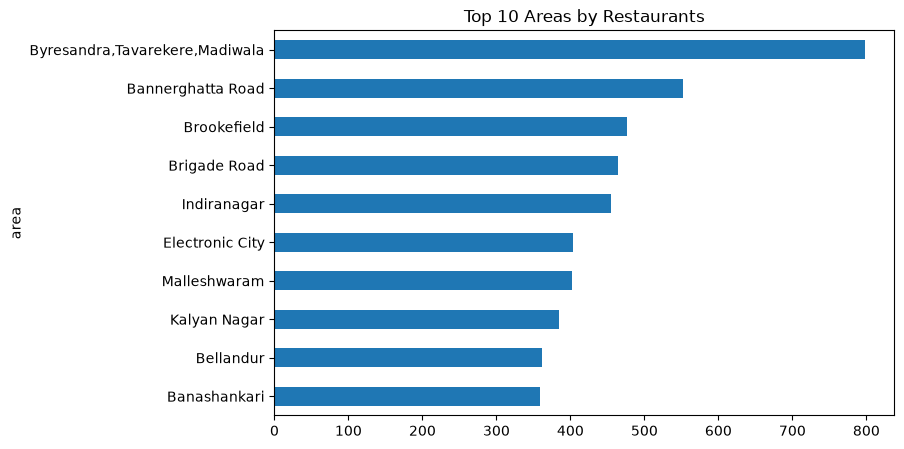

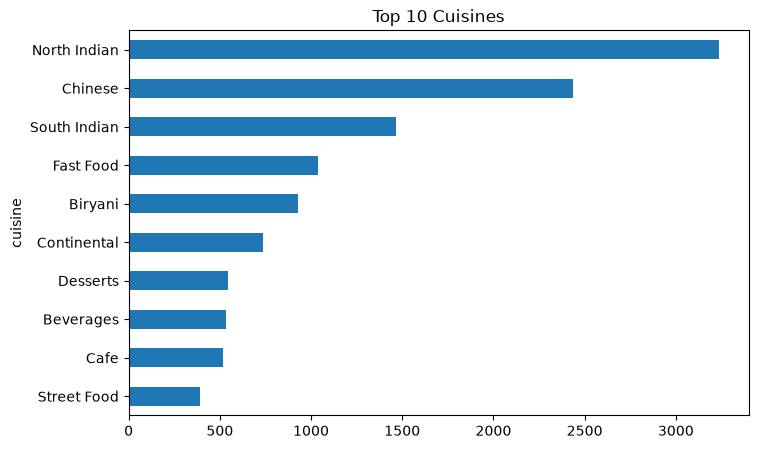

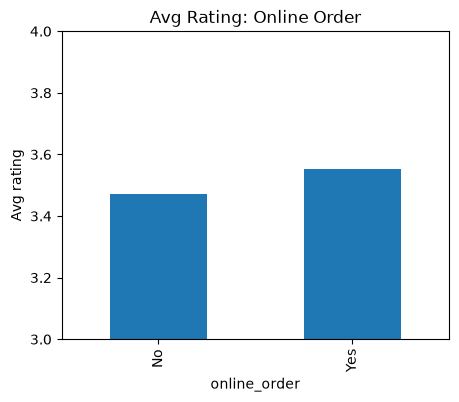

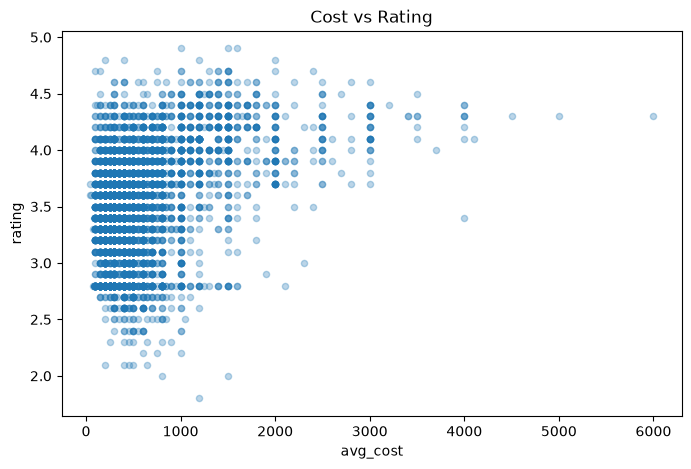

In [18]:
top_areas.plot(kind="barh", figsize=(8,5), title="Top 10 Areas by Restaurants")
plt.gca().invert_yaxis(); plt.show()

top_cuisines.plot(kind="barh", figsize=(8,5), title="Top 10 Cuisines")
plt.gca().invert_yaxis(); plt.show()

df.groupby("online_order")["rating"].mean().plot(kind="bar", figsize=(5,4), title="Avg Rating: Online Order")
plt.ylabel("Avg rating"),plt.ylim(3,4);plt.show()

df.plot(kind="scatter", x="avg_cost", y="rating", alpha=0.3, figsize=(8,5), title="Cost vs Rating")
plt.show()